# Lab 1 — Interpretable by Design Models


---

This lab covers three **interpretable-by-design** classifiers and how to extract meaningful explanations from each:

| Model | Interpretability type |
|---|---|
| **Decision Tree** | Global (tree structure, feature importance, depth trade-off) + Local (decision path) |
| **Logistic Regression** | Global (coefficients, odds ratios, correlation matrix) |
| **K-Nearest Neighbors** | Local (example-based, neighbor inspection + visualisation) |

**Guide:**
- ⚙️ Preprocessing recap
- 🌳 Decision Tree
- 📈 Logistic Regression
- 👥 KNN

---

## ⚙️ Preprocessing Recap (~10 min)

We are using the **Diabetes prediction dataset** and the same pipeline from Lab 0.
Rather than stepping through every operation again, this section is structured as a **quick recap** —
each cell highlights one key concept with a reminder of *why* it matters.

> 💡 The goal here is to consolidate what you learned in Lab 0, not to learn new things!
> By the end of this section you should be able to answer: *what would go wrong if you skipped each step?*

### ⚙️ Step 1 — Imports & Load

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn import tree

#### Exercise 0.1

Load the data

In [12]:
#@title Exercise 0.1 Solution

# ── Load the dataset ──────────────────────────────────────────────────────────
# Uncomment the line that matches your environment:
#df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/XAI_202627/labs/Lab01_Interpretable_by_Design/diabetes.csv')  # Google Drive
df = pd.read_csv('diabetes.csv')   # Local / GitHub

In [13]:

df.columns = [c.lower().replace('-', '_') for c in df.columns]
if 'class' in df.columns:
    df.rename(columns={'class': 'diabetes'}, inplace=True)
df['diabetes'] = (df['diabetes'].astype(str).str.strip().str.lower()
                  .map({'tested_positive': 1, 'tested_negative': 0,
                        '1': 1, '0': 0, 'positive': 1, 'negative': 0})
                  .astype(int))

print(f"Loaded {len(df)} rows  |  Columns: {df.columns.tolist()}")
df.head()

Loaded 100000 rows  |  Columns: ['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'hba1c_level', 'blood_glucose_level', 'diabetes']


,gender,age,hypertension,heart_disease,smoking_history,bmi,hba1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


### ⚙️ Step 2 — Check Class Balance & Duplicates

> 🔑 **Key reminder:** an imbalanced dataset means **accuracy is a misleading metric**.
> If 91% of patients are non-diabetic, a model that always predicts "no diabetes" gets 91% accuracy — and is completely useless.
> Always check balance *before* splitting so you can choose `stratify=` and the right evaluation metric.

In [14]:
print("Class distribution:")
print(df['diabetes'].value_counts())
print(f"\nImbalance ratio: {df['diabetes'].value_counts()[0] / df['diabetes'].value_counts()[1]:.1f}:1")

Class distribution:
diabetes
0    91500
1     8500
Name: count, dtype: int64

Imbalance ratio: 10.8:1


#### Exercise 0.2

Remove duplicates

In [15]:
#@title Exercise 0.2 Solution

#### START CODE HERE (~3 lines of code) ####
n_dupes = df.duplicated(keep=False).sum()
print(f"\nDuplicate rows: {n_dupes}")
df.drop_duplicates(inplace=True)
#### END CODE HERE ####


Duplicate rows: 6939


In [16]:
print(f"Rows after dedup: {len(df)}")
#Rows after dedup: 96146

Rows after dedup: 96146


### ⚙️ Step 3 — Stratified Train/Test Split

> 🔑 **Key reminder:** split *before* any transformation. Fitting scalers or encoders
> on the full dataset lets test-set statistics leak into your preprocessing, making
> your evaluation overly optimistic — this is called **data leakage**.
> `stratify=` preserves the class ratio in both subsets.

#### Exercise 0.3
Stratified Train/Test Split: Split 80% train / 20% test, shuffle=True, random_state=42, stratify by 'survived

In [17]:
#@title Exercise 0.3 Solution


#### START CODE HERE ####
df_train, df_test = train_test_split(df, test_size=0.2, shuffle=True, random_state=42, stratify=df['diabetes'])

#### END CODE HERE ####

In [18]:
print(f"Train: {len(df_train)} rows  |  Test: {len(df_test)} rows")
print(f"\nTrain class balance:\n{df_train['diabetes'].value_counts()}")
print(f"\nTest class balance:\n{df_test['diabetes'].value_counts()}")

Train: 76916 rows  |  Test: 19230 rows

Train class balance:
diabetes
0    70130
1     6786
Name: count, dtype: int64

Test class balance:
diabetes
0    17534
1     1696
Name: count, dtype: int64


### ⚙️ Step 4 — Feature Engineering & Encoding

> 🔑 **Key reminder:** ML models need numbers. Categorical features must be encoded,
> but the *type* of encoding matters:
> - **Ordinal Encoder** — when categories have a natural order (e.g. Child < Young < Adult < Senior)
> - **One-Hot Encoder** — when categories have no order (e.g. gender)
> Using the wrong encoder imposes false numeric relationships the model will exploit.

#### Exercise 0.4



*   Discretize age into 4 ordered bins `age_bins   = [0, 14, 24, 50, 100]
age_labels = ['Child (0-14]', 'Young (14-24]', 'Adults (24-50]', 'Senior (50+]']`
*  Merge sparse smoking categories, 'former' and 'not current' mean the same thing — combining them avoids sparse encoding
* Remove rare 'Other' gender rows (too few to encode reliably)
* Ordinal encode: smoking_history and age_disc (both have natural order)
* One-hot encode: gender (no natural order)



In [19]:
#@title Exercise 0.4 Solution

# ── Discretize age into 4 ordered bins ───────────────────────────────────────
age_bins   = [0, 14, 24, 50, 100]
age_labels = ['Child (0-14]', 'Young (14-24]', 'Adults (24-50]', 'Senior (50+]']
#### START CODE HERE (~3 lines) ####
for d in [df_train, df_test]:
    d['age_disc'] = pd.cut(d['age'], bins=age_bins, labels=age_labels) #cut() permet de diviser des données en catégories (ici l'âge)
    d.drop(columns=['age'], inplace=True) #on enlève la colonne age du coup, qui ne nous sert plus à rien
#### END CODE HERE ####

# ── Merge sparse smoking categories ──────────────────────────────────────────
# 'former' and 'not current' mean the same thing — combining them avoids sparse encoding
#### START CODE HERE  (~2 lines)####
for d in [df_train, df_test]:
    d.loc[d['smoking_history'] == 'former', 'smoking_history'] = 'not current' #remplace chaque ligne contenant 'former' pour remplacer par 'not current'
    #d['smoking_history'] == 'former' : on récupère toutes lignes de la colonne smoking_history ayant la valeur former
    #d.loc[d['smoking_history'] == 'former', 'smoking_history'] : on indique quelles lignes et quelles colonnes effectuer le changement
    #= 'not current' : on indique quoi remplacer comme valeurs à toutes les données ayant ces lignes et colonnes comme coordonnées (intersection)
#### END CODE HERE ####

# ── Remove rare 'Other' gender rows (too few to encode reliably) ──────────────
#### START CODE HERE  (~2 lines) ####
df_train = df_train[df_train['gender'] != 'Other'].copy()
df_test  = df_test[df_test['gender']  != 'Other'].copy()
#df_train['gender'] != 'Other'] : évalue chaque ligne de la colonne gender et génère une série de V/F où 'other' = F
#df_train[df_train['gender'] != 'Other']] : on recrée le tableau avec en ne conservant uniquement les lignes marquées d'un V
#.copy() : force la création du tableau en mémoire et évite tout warning
#### END CODE HERE ####

# ── Ordinal encode: smoking_history and age_disc (both have natural order) ────
#### START CODE HERE   (~4 lines) ####
smoking_order = ["never", "not current", "No Info", "current", "ever"] #0,1,2,3,4
ord_enc = OrdinalEncoder(categories=[smoking_order, age_labels])
ord_enc.fit(df_train[['smoking_history', 'age_disc']])   # fit on train only!
for d in [df_train, df_test]:
    d[['smoking_history', 'age_disc']] = ord_enc.transform(d[['smoking_history', 'age_disc']]) #transform() permet de convertir pour remplacer texte en valeurs numériques
#### END CODE HERE ####

# ── One-hot encode: gender (no natural order) ─────────────────────────────────
#Si on utilisait un encodage ordinal (0 pour Homme, 1 pour Femme), l'algorithme croirait mathématiquement qu'une femme "vaut plus" ou est "supérieure" à un homme.
#### START CODE HERE  (~7 lines) ####
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
ohe.fit(df_train[['gender']])                             # fit on train only!
for d in [df_train, df_test]:
    ohe_cols = pd.DataFrame(ohe.transform(d[['gender']]),
                            columns=ohe.get_feature_names_out(), index=d.index)
    #get_features_names_out() : permet de récupérer automatiquement les noms des étiquettes pour nommer les colonnes
    #index=d.index : force le nouveau tableau à garder les mêmes index que le tableau d'origine d, pour ne pas mélanger les lignes
    d.drop(columns=['gender'], inplace=True) #on supprime la colonne de string gender, inutile maintenant
    for col in ohe_cols.columns: #on passe en revue les 2 nouvelles colonnes crées male & female
        d[col] = ohe_cols[col]
#### END CODE HERE ####


In [22]:
print("Encoding done. Columns:", df_train.columns.tolist())
df_train.head(3)

Encoding done. Columns: ['hypertension', 'heart_disease', 'smoking_history', 'bmi', 'hba1c_level', 'blood_glucose_level', 'diabetes', 'age_disc', 'gender_Female', 'gender_Male']


,hypertension,heart_disease,smoking_history,bmi,hba1c_level,blood_glucose_level,diabetes,age_disc,gender_Female,gender_Male
79000,0,0,2.0,23.87,5.7,126,0,2.0,0.0,1.0
32011,0,0,1.0,33.03,4.0,126,0,3.0,1.0,0.0
95559,0,0,2.0,27.32,6.6,126,0,2.0,1.0,0.0


### ⚙️ Step 5 — Scaling & Final Split

> 🔑 **Key reminder:** scaling is essential for distance-based models (KNN) and
> gradient-based models (Logistic Regression), which are sensitive to feature magnitude.
> Decision trees are *scale-invariant* — they only care about split thresholds, not absolute values.
> We scale anyway so all three models share the same `X_train` / `X_test`.

#### Exercise 0.5

* Apply `MixMaxScaler()` on `scale_cols = ['bmi', 'HbA1c_level', 'blood_glucose_level', 'age_disc', 'smoking_history']
* Extract train and test `X_train`, `X_test`
* Extract train and test labels  `y_train`, `y_test`
`

In [ ]:
#@title Exercise 0.5 Solution
scale_cols = ['bmi', 'hba1c_level', 'blood_glucose_level', 'age_disc', 'smoking_history']
#### START CODE HERE (~3 lines) ####
scaler = MinMaxScaler()
df_train[scale_cols] = scaler.fit_transform(df_train[scale_cols])  # fit on train only!
df_test[scale_cols]  = scaler.transform(df_test[scale_cols])
#.fit() : calcule le min et max sur les données d'entrainement, et transform() convertit les données entre 0 et 1
#### END CODE HERE  ####

# ── Extract X / y ─────────────────────────────────────────────────────────────
#### START CODE HERE (~4 lines) ####
y_train = df_train['diabetes'];  X_train = df_train.drop('diabetes', axis=1)
y_test  = df_test['diabetes'];   X_test  = df_test.drop('diabetes',  axis=1)
#y_train et y_test : isole la colonne contenant le résultat
#X_train et X_test : tout le reste des colonnes, hors la colonne diabetes qui est enlevée avec drop()
#### END CODE HERE  ####
feature_names = X_train.columns.tolist()
print(f"X_train: {X_train.shape}  |  X_test: {X_test.shape}") #shape : (nb lignes, nb colonnes)
print(f"Features: {feature_names}")

X_train: (76902, 9)  |  X_test: (19226, 9)
Features: ['hypertension', 'heart_disease', 'smoking_history', 'bmi', 'hba1c_level', 'blood_glucose_level', 'age_disc', 'gender_Female', 'gender_Male']


> ✅ **Preprocessing complete.** The three rules to always remember:
> 1. Split *before* fitting any transformer
> 2. Fit transformers on training data only, then `.transform()` both sets
> 3. Choose your encoding based on whether categories have a natural order

---

## Exercise 1 — Decision Tree 🌳

Decision trees are **interpretable by design**: the tree structure *is* the explanation — no separate explanation method needed.

They give a **transparent** and **intuitive** representation of the decision-making
process followed by the model. This transparency allows domain experts to easily
understand and validate the model's predictions.

---

**Global interpretability** — inspecting the whole tree. . The measures for the global interpretability are:
- **Depth** → shallower = simpler, more interpretable
- **Node count / splits** → proxy for complexity. A larger tree with more nodes and splits may capture intricate
patterns in the data but could also lead to overtting and decreased
interpretability
- **Feature importances** → which features drive most decisions (via Gini impurity reduction)

**Local interpretability** — local path for a single prediction.Then, as mesures for the local interpretability there is:
- **Length of the decision path** → the exact sequence of rules that routed this instance to its leaf

### Your tasks
1. Fit a `DecisionTreeClassifier`.
  
> * Visualize the decision tree obtained. Are you able to interpret the decision
> * Try again with `max_depth=4` and compare the two trees. Which one is the
  most interpretable?

2. Analyze **Global Interpretability**:
Continue visualizing the obtained decision tree with `max_depth=4` .

> * Which attributes are the **most discriminating**? Plot the feature importances and then analyze the values.
> * Calculate the size of the decision tree in terms of the number of nodes,
subdivisions, and depth. How these metrics affect the interpretability of the
decision tree globally?

3. Analyze **Local Interpretability**:
Consider the instances *100, 150 and 200* of the train dataset.

> * What are the individual paths? What are the instances allocated in the
paths?
> * For each of the previous instances, calculate the **length** of each path from
the root node to the leaf node to which the instance belongs. How the
length of these paths contributes to the interpretability of the decision tree
locally?

### Exercise 1.1 — Fit & Visualise

* Train a `DecisionTreeClassifier` and plot it.
* Use the model to predict and print its accuracy

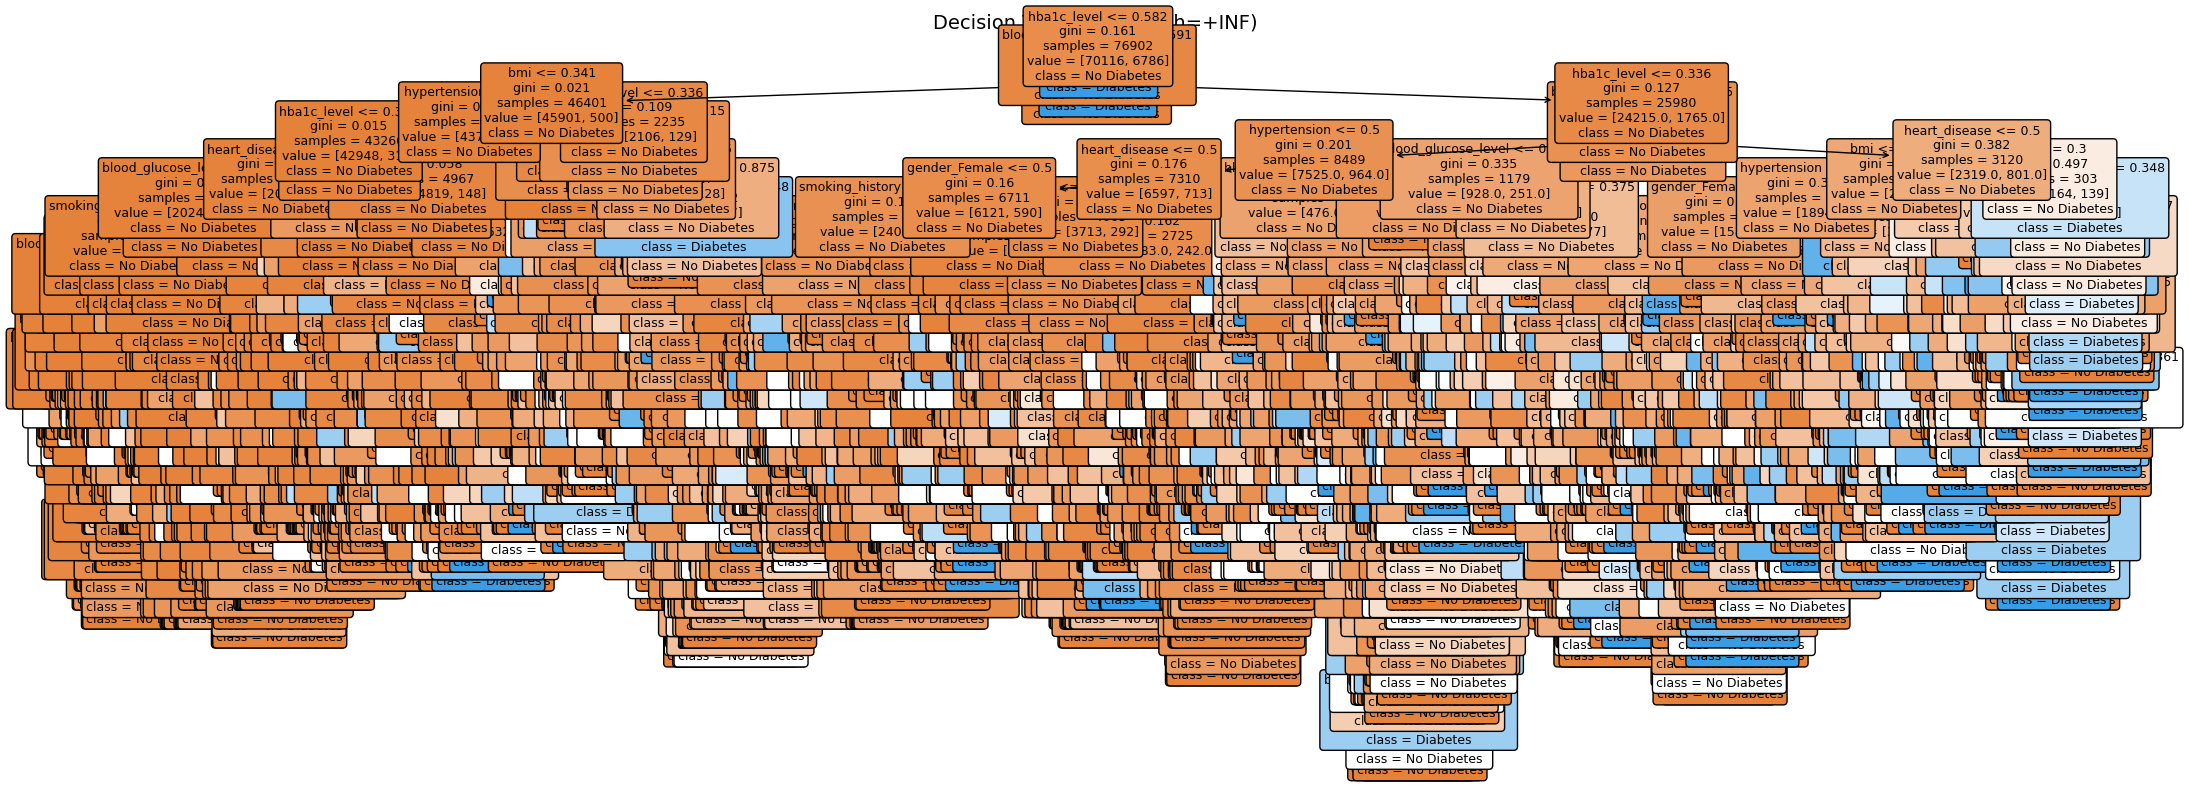

In [ ]:
#@title Exercise 1.1 Solution

from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics, confusion_matrix, ConfusionMatrixDisplay


#### START CODE HERE (~3 lines) ####
model = DecisionTreeClassifier()
model.fit(X_train,y_train) #train
#### END CODE HERE ####

# This is the code to plot the decision tree dt
plt.figure(figsize=(22, 8))
tree.plot_tree(model, feature_names=feature_names,
               class_names=['No Diabetes', 'Diabetes'],
               filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (max_depth=+INF)", fontsize=14)
plt.tight_layout()
plt.show()

In [37]:
#### START CODE HERE -- Decision Tree Predict (~2 lines) ####
y_pred = model.predict(X_test) #test
print("Model accuracy:",(metrics.accuracy_score(y_test, y_pred)))
#### END CODE HERE ####

Model accuracy: 0.9522521585353168


### Exercise 1.2 — Max Depth 4

* Train a decision tree of max depth 4
* Plot it
* create `classification_report`  and `ConfusionMatrixDisplay`

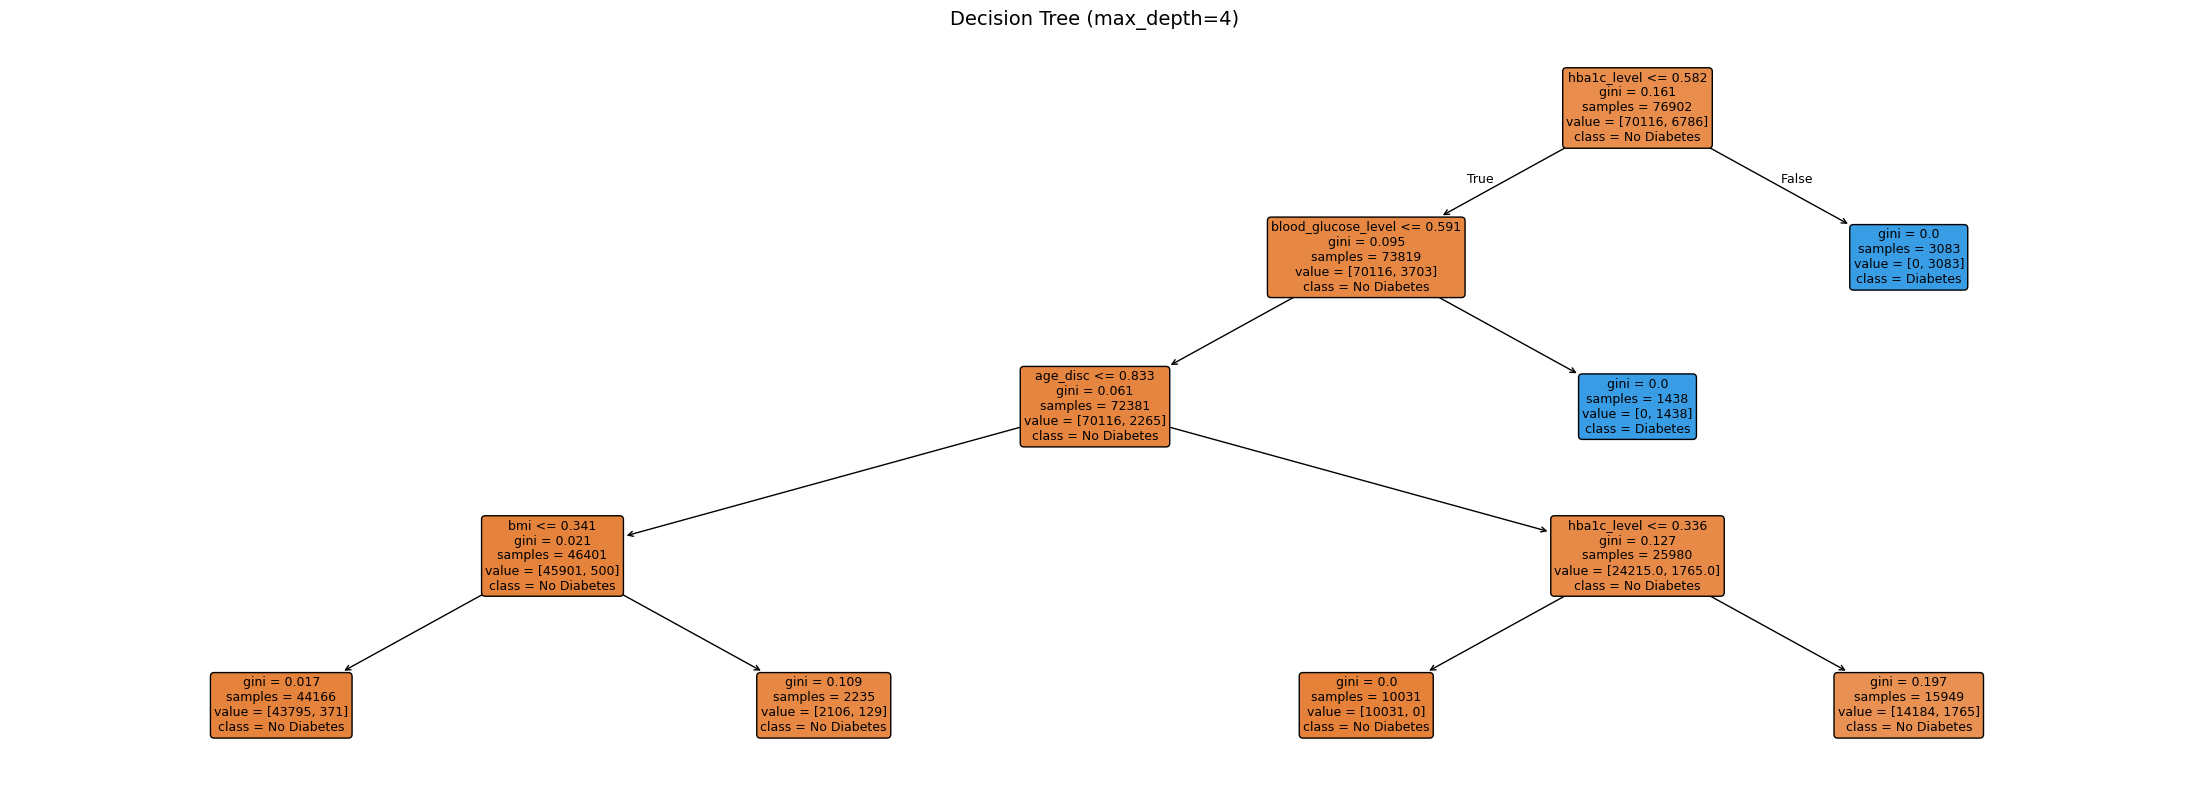

In [ ]:
#@title Exercise 1.2 Solution


#### START CODE HERE -- Decision Tree max_depth=4 ####
new_model = DecisionTreeClassifier(max_depth=4) #max_depth = 4
new_model.fit(X_train,y_train) #fit

# This is the code to plot the decision tree dt
plt.figure(figsize=(22, 8))
tree.plot_tree(new_model, feature_names=feature_names,
               class_names=['No Diabetes', 'Diabetes'],
               filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (max_depth=4)", fontsize=14)
plt.tight_layout()
plt.show()
#### END CODE HERE ####

New Model accuracy: 0.9716009570373453
Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.97      0.97     17530
           1       0.73      0.73      0.73      1696

    accuracy                           0.95     19226
   macro avg       0.85      0.85      0.85     19226
weighted avg       0.95      0.95      0.95     19226



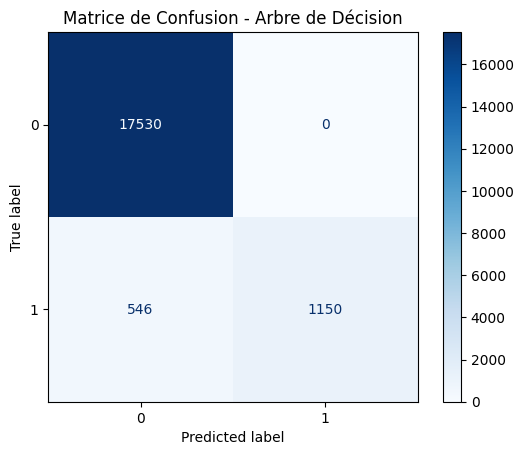

In [45]:
new_y_pred = new_model.predict(X_test)
print("New Model accuracy:",(metrics.accuracy_score(y_test, new_y_pred)))
print("Classification Report:\n", classification_report(y_test, y_pred))

disp = ConfusionMatrixDisplay.from_estimator(
    new_model, 
    X_test, 
    y_test, 
    cmap=plt.cm.Blues
)

plt.title("Matrice de Confusion - Arbre de Décision")
plt.show()

#### Exercise 1.2b

* Create a 'Depth vs Accuracy' loop ranging over different depth sizes (e.g., `depths = range(1, 10)`)  
* return the best performing tree

In [50]:
#@title Exercise 1.2b Solution


# ── Depth vs Accuracy ────────────────────────────────────────
depths = range(1, 10)
train_accs, test_accs = [], []

#### START CODE HERE ####
for d in depths: #on teste toutes les profondeurs de 1 à 10

    dtc = DecisionTreeClassifier(max_depth=d,random_state=42)
    dtc.fit(X_train,y_train)
    train_accs.append(dtc.score(X_train,y_train))
    test_accs.append(dtc.score(X_test,y_test))



#### END CODE HERE ####

best_test_depth = depths[np.argmax(test_accs)]
print(f"Best depth by test accuracy: {best_test_depth}")
print(f"Test accuracy at depth=4: {test_accs[3]:.4f}")
print(f"Test accuracy at best depth ({best_test_depth}): {max(test_accs):.4f}")

Best depth by test accuracy: 2
Test accuracy at depth=4: 0.9716
Test accuracy at best depth (2): 0.9716


### Exercise 1.3 — Global Interpretability

* Print and plot the feature importances `model.feature_importances_`
* Print the number of nodes
* Print the number of splits
* Print the depth




[0.00453517 0.00556203 0.03106577 0.15828358 0.50663044 0.27471213
 0.01005317 0.00512194 0.00403576]


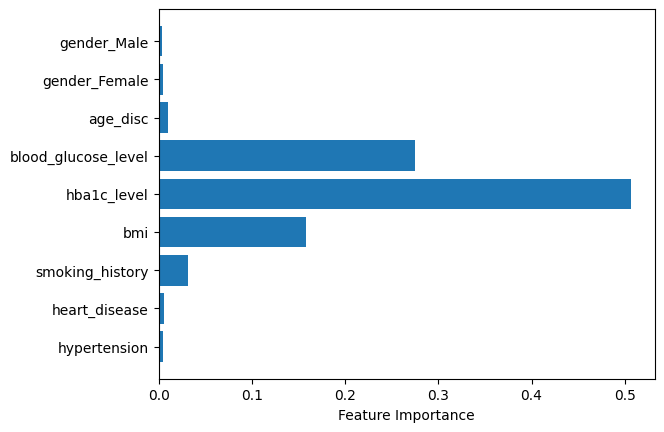

In [75]:
#@title Exercise 1.3 Solution

#### START CODE HERE -- feature importance ####
fi = model.feature_importances_
print(fi)

plt.barh(feature_names,fi)
plt.xlabel('Feature Importance')
plt.show()
#### END CODE HERE ####


In [65]:
#### START CODE HERE -- number of nodes ####
nodes_number = model.tree_.node_count
print("Nodes number:", nodes_number)
#### END CODE HERE ####


Nodes number: 7407


In [66]:
#### START CODE HERE -- number of splits ####
splits_number = ((nodes_number - 1) / 2) #Nombre total de noeuds = (Nombre de splits * 2) + 1 --> pour un ABR
print("Splits number:", splits_number)
#### END CODE HERE ####


Splits number: 3703.0


In [67]:

#### START CODE HERE -- depth ####
depth = model.get_depth()
print("Depth: ",depth)
#### END CODE HERE ####

Depth:  37


### Exercise 1.4 — Local Interpretability: Decision Paths

Consider the instances *100, 150 and 200* of the train dataset.

* Find the individual paths of the instances.
* For each of the previous instances, calculate the length of each path from
the root node to the leaf node to which the instance belongs.

An individual path will look like

```

Instance 100 | Predicted: Diabetes | Actual: Diabetes
Path length: 2 nodes
  Node 0: hba1c_level = 0.855  >  0.582
  → Leaf 10: class = Diabetes

```

* How does the
length of these paths contribute to the interpretability of the decision tree
locally?

In [68]:
#@title Exercise 1.4 Solution

print("\n--- Local Interpretability: Decision Paths ---")
instance_indices = [100, 150, 200]

#### START CODE HERE -- Decision Tree Local Interpretability ####
node_indicator = model.decision_path(X_train)
leaf_id = model.apply(X_train)
threshold = model.tree_.threshold
feature_idx = model.tree_.feature

for sample_id in instance_indices:
    node_ids = node_indicator[sample_id].indices
    pred = model.predict(X_train.iloc[[sample_id]])[0]
    actual = y_train.iloc[sample_id]
    print(f"\n{'─'*55}")
    print(f"Instance {sample_id} | Predicted: {'Diabetes' if pred==1 else 'No Diabetes'} | Actual: {'Diabetes' if actual==1 else 'No Diabetes'}")
    print(f"Path length: {len(node_ids)} nodes")
    for node_id in node_ids[:-1]:
        feat = feature_names[feature_idx[node_id]]
        thresh = threshold[node_id]
        val = X_train.iloc[sample_id, feature_idx[node_id]]
        direction = "<=" if val <= thresh else ">"
        print(f"  Node {node_id}: {feat} = {val:.3f}  {direction}  {thresh:.3f}")
    print(f"  → Leaf {leaf_id[sample_id]}: class = {'Diabetes' if pred==1 else 'No Diabetes'}")
#### END CODE HERE ####


--- Local Interpretability: Decision Paths ---

───────────────────────────────────────────────────────
Instance 100 | Predicted: Diabetes | Actual: Diabetes
Path length: 2 nodes
  Node 0: hba1c_level = 0.855  >  0.582
  → Leaf 7406: class = Diabetes

───────────────────────────────────────────────────────
Instance 150 | Predicted: No Diabetes | Actual: No Diabetes
Path length: 26 nodes
  Node 0: hba1c_level = 0.491  <=  0.582
  Node 1: blood_glucose_level = 0.295  <=  0.591
  Node 2: age_disc = 1.000  >  0.833
  Node 2242: hba1c_level = 0.491  >  0.336
  Node 2244: blood_glucose_level = 0.295  >  0.150
  Node 2246: bmi = 0.210  <=  0.244
  Node 2247: hypertension = 0.000  <=  0.500
  Node 2248: heart_disease = 0.000  <=  0.500
  Node 2249: gender_Female = 1.000  >  0.500
  Node 3271: bmi = 0.210  >  0.175
  Node 3509: blood_glucose_level = 0.295  <=  0.318
  Node 3510: bmi = 0.210  >  0.175
  Node 3512: bmi = 0.210  >  0.191
  Node 3564: hba1c_level = 0.491  >  0.409
  Node 3646: smo

> **Reflection:** Look at the path lengths for your three instances. A shorter path means fewer rules were needed — usually a more "clear-cut" case. Do instances with shorter paths have more extreme feature values (very high blood glucose, very high HbA1c)?

---

## Exercise 2 — Logistic Regression 📈

Logistic Regression is interpretable through its **coefficients** and derived **odds ratios**.
Unlike Linear regression, the interpretation of logistic regression weights varies since the outcome in logistic regression is a probability confined within the range of 0 to 1.
These weights undergo transformation through the logistic function, influencing the probability non-linearly.

- **Coefficient > 0** → feature increases the log-odds of the positive class (diabetes)
- **Coefficient < 0** → feature decreases the log-odds
- **Odds ratio = exp(coef)** → multiplicative change in odds for a 1-unit increase in the feature
  - OR > 1 → increases odds of diabetes
  - OR < 1 → decreases odds of diabetes
  - OR = 1 → no effect

### Your tasks
1.   Fit a [**Logistic Regression**](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression) model on the same dataset as before.

2.  Compute the Correlation Matrix.

3.  Evaluate the model using Precision, Recall and F1-score metrics.

4.  Analyze **Interpretability**:


> * Visualize the estimated **weights** and **odds ratios** obtained from logistic regression for each feature.
> * Put them into a tabular form and interpret the logistic regression model for different types of features. Specifically, analyze the ***bmi*** feature and ***gender_Male*** and ***gender_Female*** features.


### Exercise 2.1 — Fit & Evaluate

* Train a logitic regression
* Report its classification and confusion matrix

In [79]:
#@title Exercise 2.1 Solution

from sklearn.linear_model import LogisticRegression

#### START CODE HERE ####
lg = LogisticRegression(random_state=42)
lg.fit(X_train,y_train) #fit
y_pred_lr = lg.predict(X_test)
#### END CODE HERE ####


--- Classification Report (Logistic Regression) ---
              precision    recall  f1-score   support

 No Diabetes       0.96      0.99      0.98     17530
    Diabetes       0.87      0.63      0.73      1696

    accuracy                           0.96     19226
   macro avg       0.92      0.81      0.85     19226
weighted avg       0.96      0.96      0.96     19226



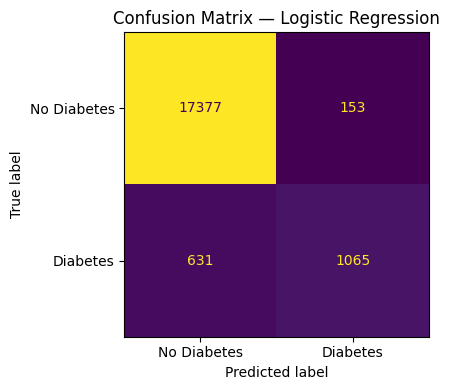

In [80]:
print("\n--- Classification Report (Logistic Regression) ---")
print(classification_report(y_test, y_pred_lr, target_names=['No Diabetes', 'Diabetes']))

cm_lr = confusion_matrix(y_test, y_pred_lr)
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=['No Diabetes','Diabetes'])
fig, ax = plt.subplots(figsize=(5, 4))
disp_lr.plot(ax=ax, colorbar=False)
ax.set_title('Confusion Matrix — Logistic Regression')
plt.tight_layout()

### Exercise 2.2 — Correlation Matrix

> 🔑 Before interpreting coefficients, always check for **multicollinearity** — when two features are
> highly correlated, the model distributes their shared explanatory power between them arbitrarily.
> This makes individual coefficients unreliable as explanations, even if the model's predictions are fine.

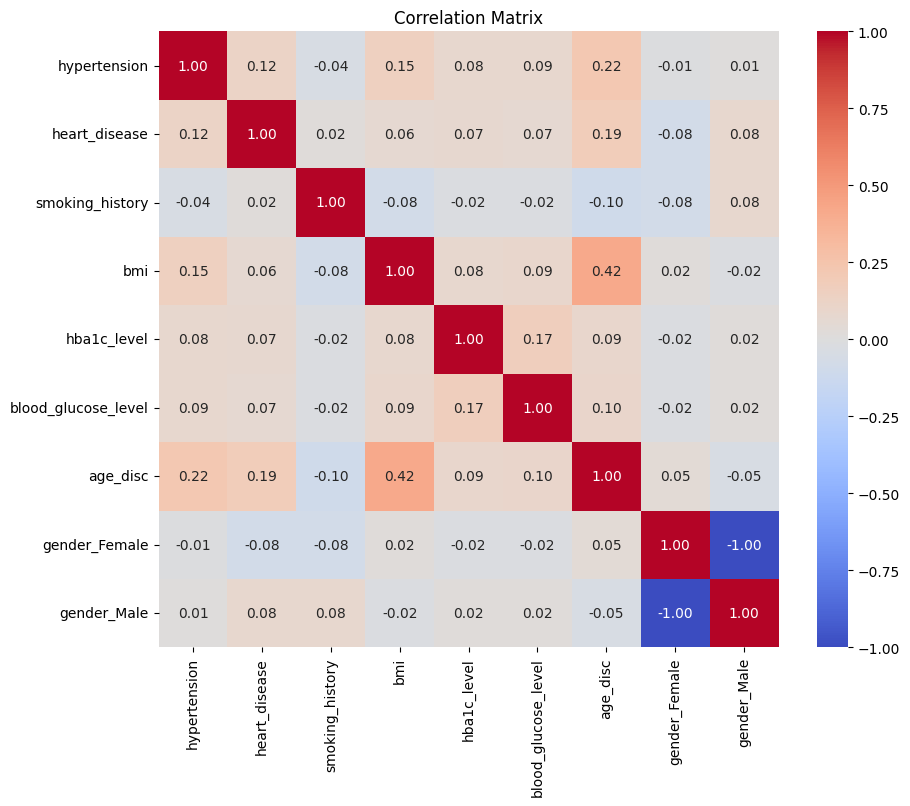

In [81]:
#@title Exercise 2.2 Solution

#### START CODE HERE (~6 lines) ####
corr_matrix = X_train.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", center=0)
plt.title('Correlation Matrix')
plt.show()
#### END CODE HERE ####

### Exercise 2.3 — Coefficients Weights & Odds Ratios

* Print and plot feature names, coefficients and odd_ratios
* Interpret the results

            Feature  Coefficient    Odds Ratio
        hba1c_level    12.056529 172220.097995
blood_glucose_level     7.138984   1260.147686
                bmi     6.179285    482.646594
           age_disc     3.441471     31.232878
      heart_disease     0.932194      2.540075
       hypertension     0.876700      2.402958
    smoking_history    -0.256792      0.773529
        gender_Male    -4.494888      0.011166
      gender_Female    -4.783915      0.008363


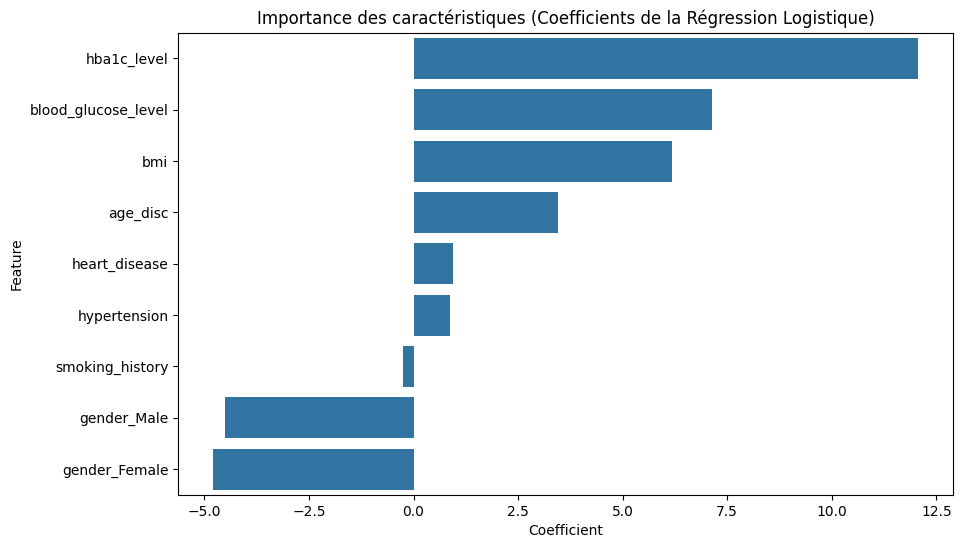

In [82]:
#@title Exercise 2.3 Solution


#### START CODE HERE ####
# Extraction des coefficients et calcul des Odds Ratios
coefficients = lg.coef_[0]
odds_ratios = np.exp(coefficients)

# Création du tableau de synthèse
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Odds Ratio': odds_ratios
})

# Affichage du tableau trié
print(coef_df.sort_values(by='Coefficient', ascending=False).to_string(index=False))

# Création du graphique des coefficients
plt.figure(figsize=(10, 6))
sns.barplot(x='Coefficient', y='Feature', data=coef_df.sort_values(by='Coefficient', ascending=False))
plt.title('Importance des caractéristiques (Coefficients de la Régression Logistique)')
plt.show()
#### END CODE HERE ####

In [83]:
# Interpretation
bmi_row = coef_df[coef_df['Feature'] == 'bmi']
male_row = coef_df[coef_df['Feature'] == 'gender_Male'] if 'gender_Male' in coef_df['Feature'].values else None
female_row = coef_df[coef_df['Feature'] == 'gender_Female'] if 'gender_Female' in coef_df['Feature'].values else None

print("\n--- Feature Interpretations ---")
if not bmi_row.empty:
    b = bmi_row.iloc[0]
    print(f"BMI: coef={b['Coefficient']:.4f}, OR={b['Odds Ratio']:.4f}")
    print(f"  → A 1-unit increase in scaled BMI multiplies diabetes odds by {b['Odds Ratio']:.2f}x")
for name, row in [('gender_Male', male_row), ('gender_Female', female_row)]:
    if row is not None and not row.empty:
        r = row.iloc[0]
        direction = "increases" if r['Odds Ratio'] > 1 else "decreases"
        print(f"{name}: coef={r['Coefficient']:.4f}, OR={r['Odds Ratio']:.4f}")
        print(f"  → Being {name.split('_')[1]} {direction} the odds of diabetes by factor {r['Odds Ratio']:.2f}")


--- Feature Interpretations ---
BMI: coef=6.1793, OR=482.6466
  → A 1-unit increase in scaled BMI multiplies diabetes odds by 482.65x
gender_Male: coef=-4.4949, OR=0.0112
  → Being Male decreases the odds of diabetes by factor 0.01
gender_Female: coef=-4.7839, OR=0.0084
  → Being Female decreases the odds of diabetes by factor 0.01


## Exercise 3 — K-Nearest Neighbors 👥

KNN is an **instance-based learner**: there are no learned weights or tree structures to inspect.
In KNN, the prediction for a new data point is determined by the **majority** **class** (for classification) or the **mean** of the closest k neighbors' values (for regression) among the training data points, where *k* is a user-defined parameter.


Finding *k* can be tricky and you typically use techniques like cross-validation, **grid search**, or random search.

The interpretation and explanation of KNN does not follow procedures similar to the ones above. This because the KNN is an **instance-based learning algorithm** and so the interpretability comes entirely from **looking at the neighbors** used to make a prediction:

> *"This patient is predicted diabetic because their **6 most similar** patients in the training set were all diabetic."*


Hence, to explain a prediction in KNN:


1.   Retrieve the *k neighbors* that were used for the prediction.
2.   Analyze the k neighbors.

Hence, this is **purely local** interpretability — each prediction gets its own explanation given by its closest example.

### Your tasks

1. Find the best `k` parameter iterating over a range (1, 15) using a [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).

> * Use the **best k** already found and fit a [**KNN**](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html) on the same dataset as before.

> * Evaluate the KNN calculating the **mean accuracy** over test dataset.

2. Analyze **Interpretability** explaining 3 instances:

> * Consider the instances 100, 150 and 200 of the train dataset.
> * **Check** the **predicted target** for each instance.
> * **Retrieve** the relative k-nearest neighbors.
> * To **explain** the **predicted target** check the predicted targets for each of the k-nearest neighbors.

### Exercise 3.1 — Grid Search for Best K

* Use `GridSearchCV` to find the best k
* Print the best accuracy
* Plot  k vs accuracy

In [ ]:
#@title Exercise 3.1 Solution

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

#### START CODE HERE (~5 lines) ####

#### END CODE HERE ####

print(f"Best k = {best_k}  (CV accuracy = {knn_cv.best_score_:.4f})")
Best k = 6  (CV accuracy = 0.9629)

In [ ]:
# Plot CV scores
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, 15), cv_results['mean_test_score'], 'o-', color='darkorange', label='CV mean accuracy')
ax.fill_between(range(1, 15),
                cv_results['mean_test_score'] - cv_results['std_test_score'],
                cv_results['mean_test_score'] + cv_results['std_test_score'],
                alpha=0.2, color='darkorange')
ax.axvline(best_k, color='red', linestyle='--', label=f'Best k={best_k}')
ax.set_xlabel('k (n_neighbors)')
ax.set_ylabel('CV Accuracy')
ax.set_title('KNN Grid Search — k vs. Cross-Validation Accuracy')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()

In [ ]:
# Fit final KNN with best k

#### START CODE HERE (~2 lines) ####


#### END CODE HERE ####

### Exercise 3.2 — Mean Accuracy over test dataset

* Compute the mean accuracy on test set
* Print/plot the classification report and confusion matrix

In [ ]:
#@title Exercise 3.2 Solution

#### START CODE HERE ####

#### END CODE HERE ####

### Exercise 3.3 — Explain 3 instances

* Explain instances [100, 150, 200] by inspecting the KNN model (`knn.kneighbors`)
* You should be able to generate an explanation in this format:
```
Instance 100
  Predicted : Diabetes
  Actual    : Diabetes
  k=6 neighbors → 6 Diabetes | 0 No Diabetes
  Confidence: 100% majority vote

  Neighbors (key features):
```



In [ ]:
#@title Exercise 3.3 Solution

#### START CODE HERE ####

#### END CODE HERE ####

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, sample_id in zip(axes, [100, 150, 200]):
    instance = X_train.iloc[[sample_id]]
    predicted = knn.predict(instance)[0]
    _, neighbor_indices = knn.kneighbors(instance)
    neighbor_labels = y_train_arr[neighbor_indices[0]]
    n_d = int(neighbor_labels.sum())
    n_n = best_k - n_d
    ax.bar(['Diabetes', 'No Diabetes'], [n_d, n_n],
           color=['tomato', 'steelblue'])
    ax.set_title(f"Instance {sample_id}\nPred: {'Diabetes' if predicted==1 else 'No Diabetes'}")
    ax.set_ylabel('# Neighbors')
    ax.set_ylim(0, best_k + 1)
plt.suptitle(f'KNN (k={best_k}) — Neighbor Vote Breakdown', fontsize=12)
plt.tight_layout()

### 🔍 Reflection Questions

1. **Decision Tree:** The depth–accuracy plot shows that depth=4 costs some performance. Is that trade-off justified for a medical application like diabetes prediction — and *who* needs to read this model (clinician? regulator? patient)?

2. **Logistic Regression:** `blood_glucose_level` and `HbA1c_level` are likely correlated. If both have large positive coefficients, can you trust either one in isolation as an explanation? What would you do before presenting these to a doctor?

3. **KNN:** When an instance's neighbors are split (e.g. 4 vs. 2), the model is less "certain". How could you expose that uncertainty meaningfully? Would a clinician trust a prediction backed by only 4 out of 6 neighbors?

4. **General:** All three models are "interpretable by design" — but is interpretability the same as trustworthiness? Can you construct a scenario where a shallow Decision Tree gives a confidently *wrong* explanation?